# Import libaraies

In [132]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import MinMaxScaler, OneHotEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.naive_bayes import MultinomialNB, GaussianNB
from sklearn.model_selection import train_test_split, cross_val_score, cross_validate, GridSearchCV
from sklearn.metrics import classification_report, roc_auc_score, roc_curve
import joblib
# from google.colab import files

# Read Dataset

In [133]:
# files.upload()
df = pd.read_csv("./WA_Fn-UseC_-Telco-Customer-Churn.csv")

In [134]:
df.head()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


# Features

## Who the customer is
- gender — the customer's gender
- SeniorCitizen — whether the customer is a senior citizen
- Partner — whether the customer has a spouse or partner living with them
- Dependents — whether the customer has dependents (kids, elderly parents, etc. relying on them)

## Their relationship with the company
- tenure — how many months they've been a customer so far
- Contract — what type of contract they're on: paying month-to-month with no commitment, or locked into a 1-year or 2-year agreement
- PaperlessBilling — whether they receive bills electronically instead of paper mail
- PaymentMethod — how they pay their bill (electronic check, mailed check, automatic bank transfer, or automatic credit card charge)
- MonthlyCharges — how much they're billed each month
- TotalCharges — the total amount they've paid the company across their entire time as a customer

## What services they've subscribed to

- PhoneService — whether they have a home phone line through this company
- MultipleLines — whether they have more than one phone line
- InternetService — what kind of internet they have (DSL, Fiber optic, or none)
- OnlineSecurity — whether they've added an online security add-on service
- OnlineBackup — whether they've added a cloud backup service
- DeviceProtection — whether they've added insurance/protection for their equipment (router, etc.)
- TechSupport — whether they've added a premium tech support service
- StreamingTV — whether they use the company's TV streaming service
- StreamingMovies — whether they use the company's movie streaming service

## The outcome you're predicting

- Churn — whether the customer ultimately left the company (cancelled service) or stayed

# EDA

In [135]:
df.isna().sum()

customerID          0
gender              0
SeniorCitizen       0
Partner             0
Dependents          0
tenure              0
PhoneService        0
MultipleLines       0
InternetService     0
OnlineSecurity      0
OnlineBackup        0
DeviceProtection    0
TechSupport         0
StreamingTV         0
StreamingMovies     0
Contract            0
PaperlessBilling    0
PaymentMethod       0
MonthlyCharges      0
TotalCharges        0
Churn               0
dtype: int64

In [136]:
df.duplicated().sum()

np.int64(0)

In [137]:
df.shape

(7043, 21)

In [138]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   str    
 1   gender            7043 non-null   str    
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   str    
 4   Dependents        7043 non-null   str    
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   str    
 7   MultipleLines     7043 non-null   str    
 8   InternetService   7043 non-null   str    
 9   OnlineSecurity    7043 non-null   str    
 10  OnlineBackup      7043 non-null   str    
 11  DeviceProtection  7043 non-null   str    
 12  TechSupport       7043 non-null   str    
 13  StreamingTV       7043 non-null   str    
 14  StreamingMovies   7043 non-null   str    
 15  Contract          7043 non-null   str    
 16  PaperlessBilling  7043 non-null   str    
 17  Paymen

In [139]:
for feature in df.columns.drop('customerID'):
  print(feature, df[feature].unique())

gender <ArrowStringArray>
['Female', 'Male']
Length: 2, dtype: str
SeniorCitizen [0 1]
Partner <ArrowStringArray>
['Yes', 'No']
Length: 2, dtype: str
Dependents <ArrowStringArray>
['No', 'Yes']
Length: 2, dtype: str
tenure [ 1 34  2 45  8 22 10 28 62 13 16 58 49 25 69 52 71 21 12 30 47 72 17 27
  5 46 11 70 63 43 15 60 18 66  9  3 31 50 64 56  7 42 35 48 29 65 38 68
 32 55 37 36 41  6  4 33 67 23 57 61 14 20 53 40 59 24 44 19 54 51 26  0
 39]
PhoneService <ArrowStringArray>
['No', 'Yes']
Length: 2, dtype: str
MultipleLines <ArrowStringArray>
['No phone service', 'No', 'Yes']
Length: 3, dtype: str
InternetService <ArrowStringArray>
['DSL', 'Fiber optic', 'No']
Length: 3, dtype: str
OnlineSecurity <ArrowStringArray>
['No', 'Yes', 'No internet service']
Length: 3, dtype: str
OnlineBackup <ArrowStringArray>
['Yes', 'No', 'No internet service']
Length: 3, dtype: str
DeviceProtection <ArrowStringArray>
['No', 'Yes', 'No internet service']
Length: 3, dtype: str
TechSupport <ArrowStringArray>


In [140]:
numerical_features = ['tenure', 'MonthlyCharges', 'TotalCharges']
categorical_features = [
    'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection',
    'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaymentMethod']
binary_features =['gender', 'SeniorCitizen', 'Partner', 'Dependents', 'PhoneService', 'PaperlessBilling', 'Churn']

In [141]:
df[binary_features]

,gender,SeniorCitizen,Partner,Dependents,PhoneService,PaperlessBilling,Churn
0,Female,0,Yes,No,No,Yes,No
1,Male,0,No,No,Yes,No,No
2,Male,0,No,No,Yes,Yes,Yes
3,Male,0,No,No,No,No,No
4,Female,0,No,No,Yes,Yes,Yes
...,...,...,...,...,...,...,...
7038,Male,0,Yes,Yes,Yes,Yes,No
7039,Female,0,Yes,Yes,Yes,Yes,No
7040,Female,0,Yes,Yes,No,Yes,No
7041,Male,1,Yes,No,Yes,Yes,Yes


In [142]:
print(len(numerical_features + categorical_features + binary_features))
print(len(df.columns))

20
21


# Cleaning Data

In [143]:
df[(df['TotalCharges'] == ' ') & (df['tenure']== 0)]

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
488,4472-LVYGI,Female,0,Yes,Yes,0,No,No phone service,DSL,Yes,...,Yes,Yes,Yes,No,Two year,Yes,Bank transfer (automatic),52.55,,No
753,3115-CZMZD,Male,0,No,Yes,0,Yes,No,No,No internet service,...,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,20.25,,No
936,5709-LVOEQ,Female,0,Yes,Yes,0,Yes,No,DSL,Yes,...,Yes,No,Yes,Yes,Two year,No,Mailed check,80.85,,No
1082,4367-NUYAO,Male,0,Yes,Yes,0,Yes,Yes,No,No internet service,...,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,25.75,,No
1340,1371-DWPAZ,Female,0,Yes,Yes,0,No,No phone service,DSL,Yes,...,Yes,Yes,Yes,No,Two year,No,Credit card (automatic),56.05,,No
3331,7644-OMVMY,Male,0,Yes,Yes,0,Yes,No,No,No internet service,...,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,19.85,,No
3826,3213-VVOLG,Male,0,Yes,Yes,0,Yes,Yes,No,No internet service,...,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,25.35,,No
4380,2520-SGTTA,Female,0,Yes,Yes,0,Yes,No,No,No internet service,...,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,20.00,,No
5218,2923-ARZLG,Male,0,Yes,Yes,0,Yes,No,No,No internet service,...,No internet service,No internet service,No internet service,No internet service,One year,Yes,Mailed check,19.70,,No
6670,4075-WKNIU,Female,0,Yes,Yes,0,Yes,Yes,DSL,No,...,Yes,Yes,Yes,No,Two year,No,Mailed check,73.35,,No


In [144]:
df['TotalCharges'] = pd.to_numeric(df['TotalCharges'], errors='coerce')

In [145]:
df['TotalCharges'].isna().sum()

np.int64(11)

In [146]:
df['TotalCharges'] = df['TotalCharges'].fillna(0)

In [147]:
(df['TotalCharges'] == 0.0).sum()

np.int64(11)

In [148]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   str    
 1   gender            7043 non-null   str    
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   str    
 4   Dependents        7043 non-null   str    
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   str    
 7   MultipleLines     7043 non-null   str    
 8   InternetService   7043 non-null   str    
 9   OnlineSecurity    7043 non-null   str    
 10  OnlineBackup      7043 non-null   str    
 11  DeviceProtection  7043 non-null   str    
 12  TechSupport       7043 non-null   str    
 13  StreamingTV       7043 non-null   str    
 14  StreamingMovies   7043 non-null   str    
 15  Contract          7043 non-null   str    
 16  PaperlessBilling  7043 non-null   str    
 17  Paymen

In [149]:
df[(df['TotalCharges'] != 0) & (df['tenure'] == 0)]

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn


In [150]:
len(df[(df['tenure'] == 0) & (df['MonthlyCharges'] != 0)])

11

In [151]:
df[df['tenure'] == 0]['MonthlyCharges']

488     52.55
753     20.25
936     80.85
1082    25.75
1340    56.05
3331    19.85
3826    25.35
4380    20.00
5218    19.70
6670    73.35
6754    61.90
Name: MonthlyCharges, dtype: float64

In [152]:
len(df[(df['MonthlyCharges'] != 0) & (df['TotalCharges'] == 0)])

11

In [153]:
df[df['TotalCharges'] == 0]['MonthlyCharges']

488     52.55
753     20.25
936     80.85
1082    25.75
1340    56.05
3331    19.85
3826    25.35
4380    20.00
5218    19.70
6670    73.35
6754    61.90
Name: MonthlyCharges, dtype: float64

# EDA Con.

In [154]:
df[numerical_features].describe()

,tenure,MonthlyCharges,TotalCharges
count,7043.000000,7043.000000,7043.000000
mean,32.371149,64.761692,2279.734304
std,24.559481,30.090047,2266.794470
min,0.000000,18.250000,0.000000
25%,9.000000,35.500000,398.550000
50%,29.000000,70.350000,1394.550000
75%,55.000000,89.850000,3786.600000
max,72.000000,118.750000,8684.800000


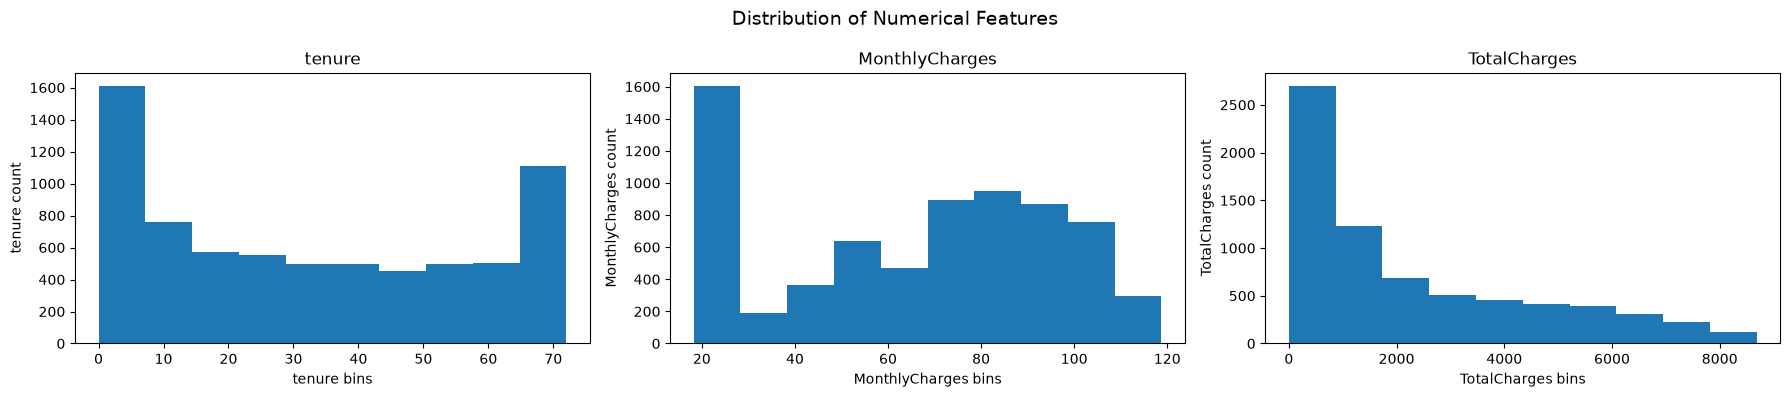

In [155]:
fig, axes = plt.subplots(1, 3, figsize=(18, 4))
for i, feature in enumerate(numerical_features):
  axes[i].set_title(feature)
  axes[i].hist(df[feature])
  axes[i].set_xlabel(f'{feature} bins')
  axes[i].set_ylabel(f'{feature} count')
fig.suptitle('Distribution of Numerical Features', fontsize=14)
plt.tight_layout()
plt.show()

In [156]:
print("""
We can conclude that
- tenure & MonthlyCharges are bimodal shapes
- TotalCharges is right-skew
""")


We can conclude that
- tenure & MonthlyCharges are bimodal shapes
- TotalCharges is right-skew



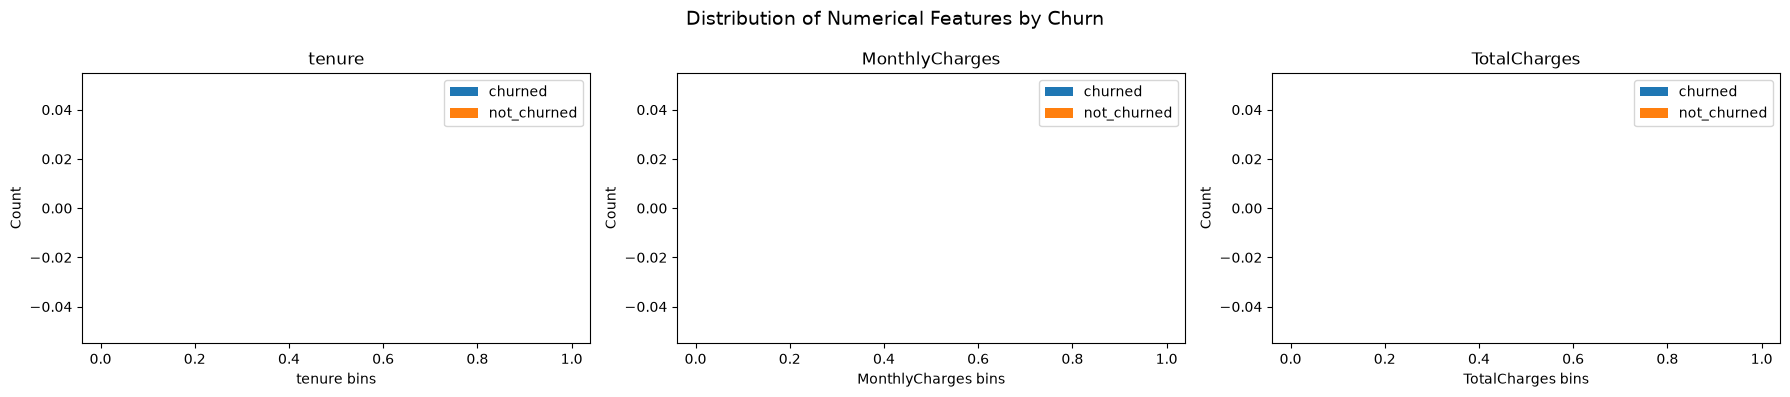

In [157]:
fig, axes = plt.subplots(1, 3, figsize=(18, 4))
for i, feature in enumerate(numerical_features):
    churned = df[df['Churn'] == 1][feature]
    not_churned = df[df['Churn'] == 0][feature]
    axes[i].hist([not_churned, churned])
    axes[i].set_title(feature)
    axes[i].set_xlabel(f'{feature} bins')
    axes[i].set_ylabel('Count')
    axes[i].legend(['churned', 'not_churned'])
fig.suptitle('Distribution of Numerical Features by Churn', fontsize=14)
plt.tight_layout()
plt.show()

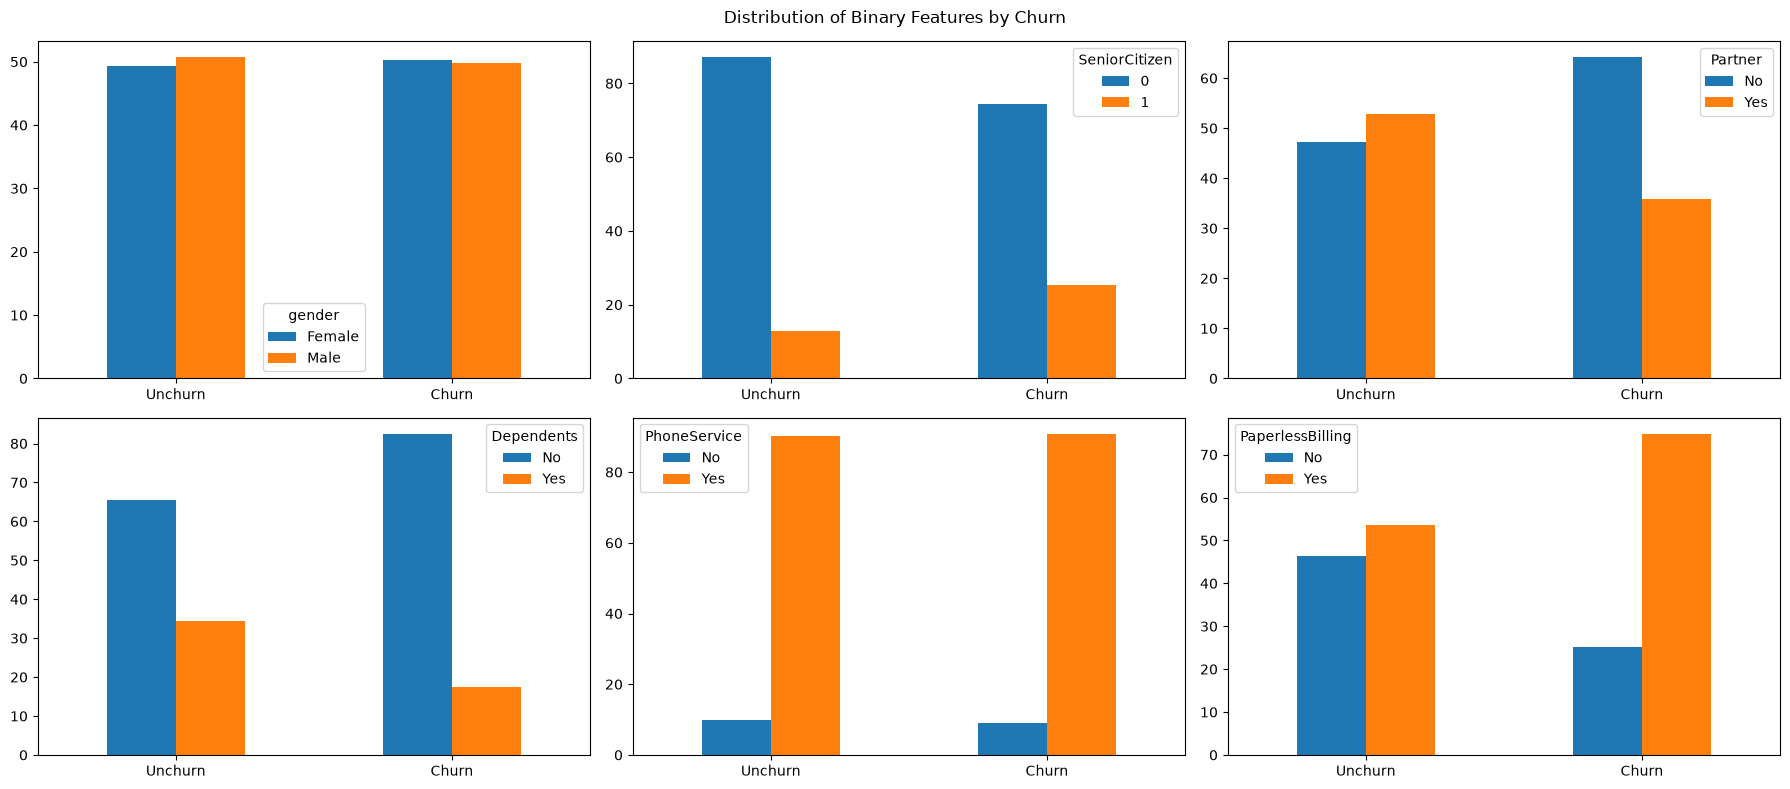

In [158]:
binary_features_without_target = [f for f in binary_features if f != 'Churn']
fig, axes = plt.subplots(2, 3, figsize=(18, 8))
fig.suptitle("Distribution of Binary Features by Churn")
for i, feature in enumerate(binary_features_without_target):
  ax = axes.flat[i]
  churn_cases = (df.groupby('Churn')[feature].value_counts(normalize=True) * 100).unstack(fill_value=0).sort_index()
  churn_cases.index=['Unchurn', 'Churn']
  churn_cases.plot(kind='bar', ax=ax)
  ax.tick_params(axis='x',rotation=0)
plt.tight_layout()
plt.show()

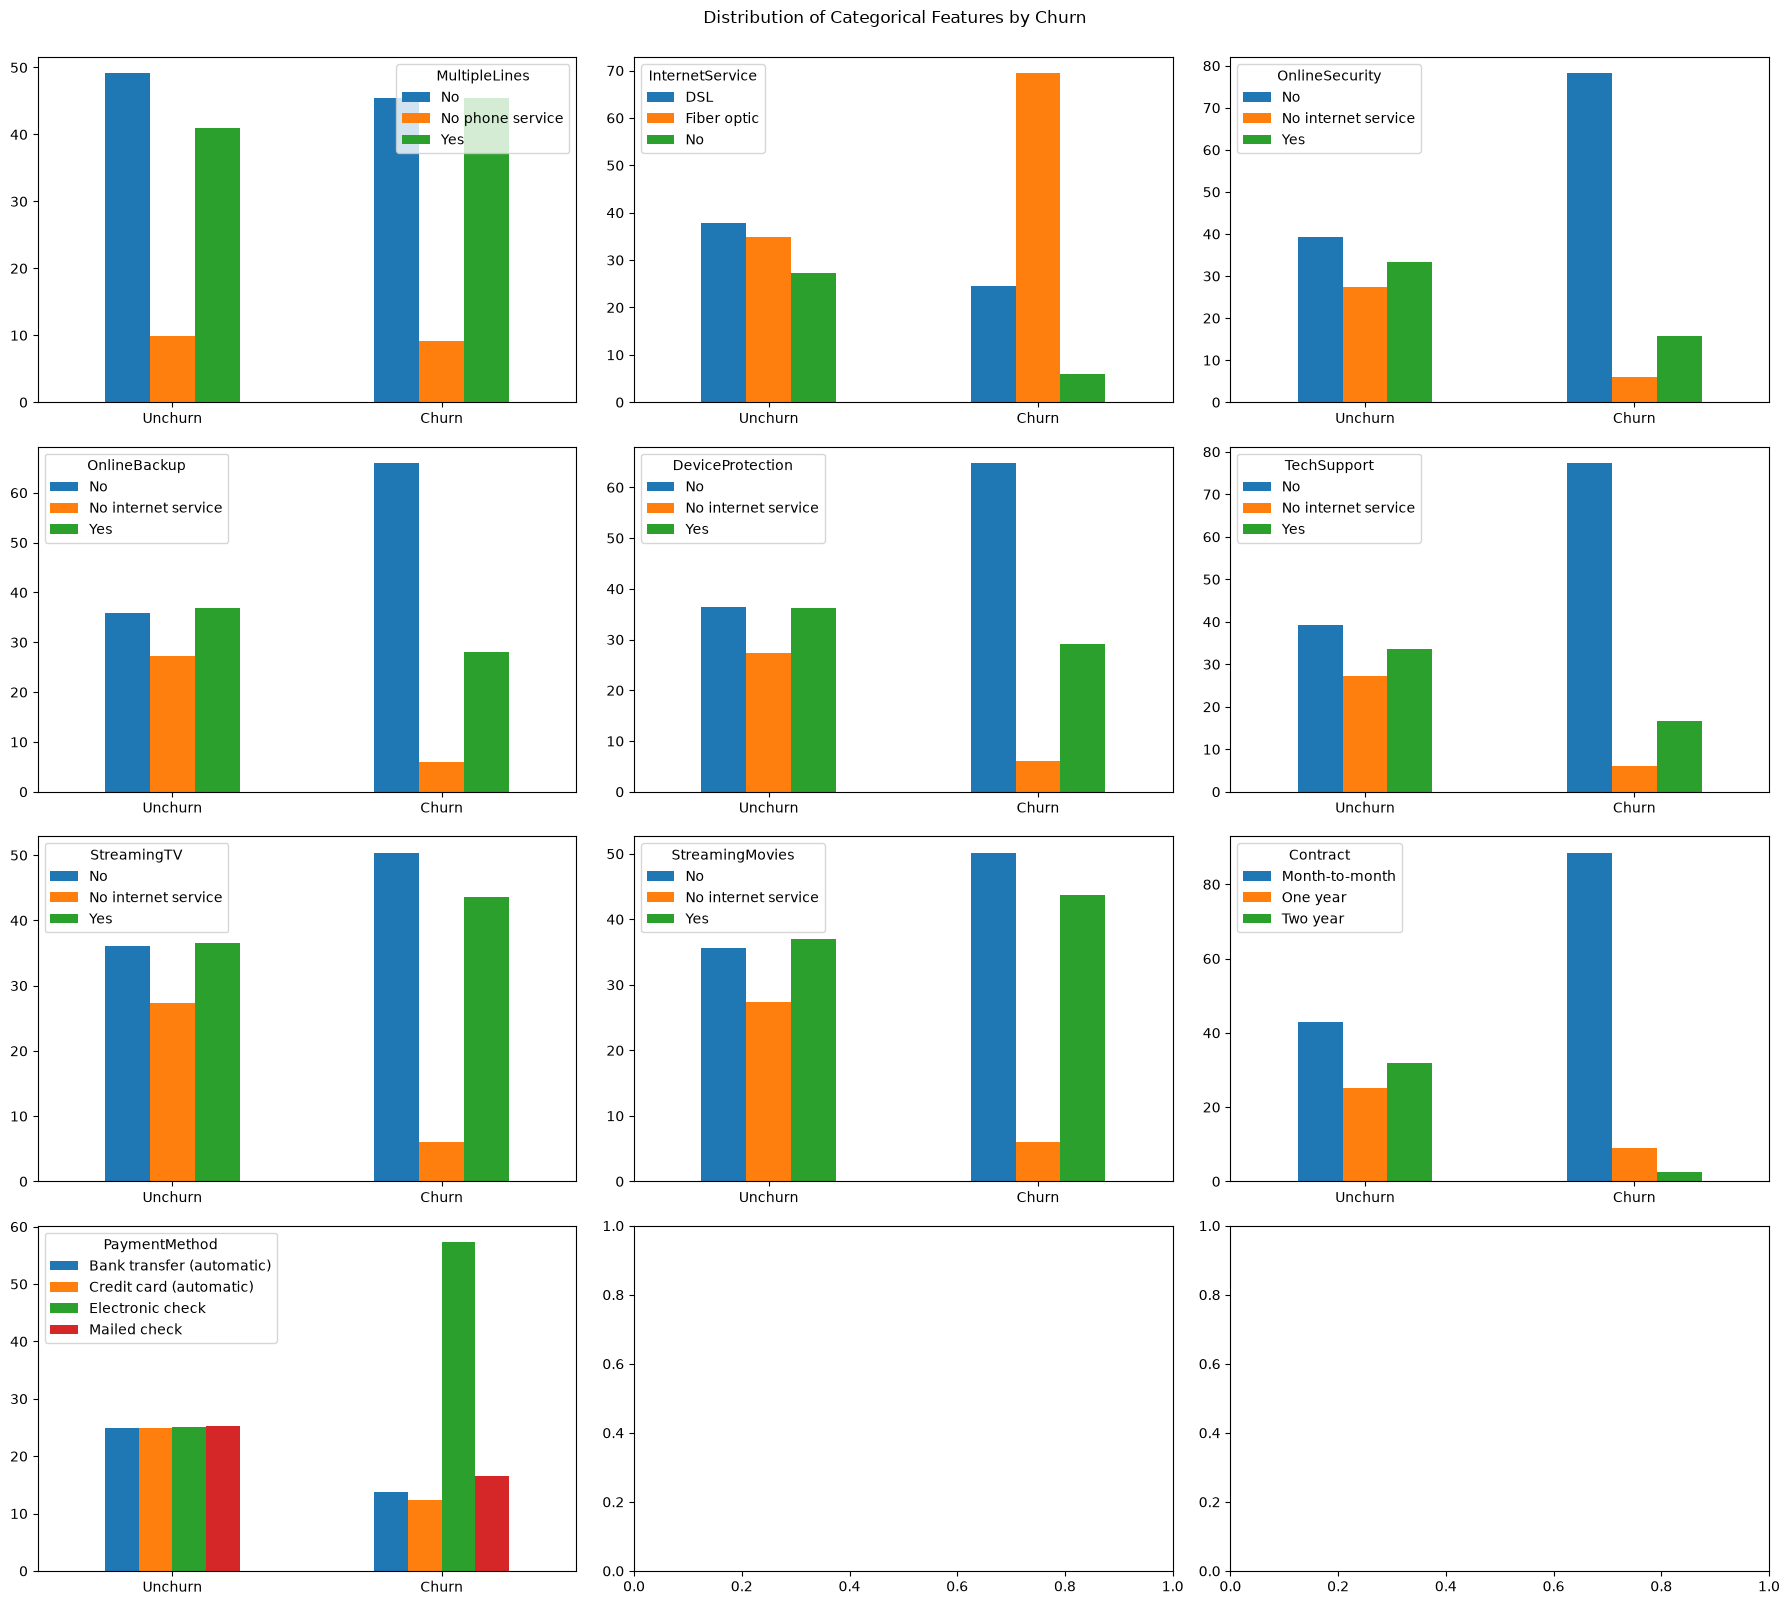

In [159]:
fig, axes = plt.subplots(4, 3, figsize=(18, 16))
fig.suptitle("Distribution of Categorical Features by Churn", y = 1)
for i, feature in enumerate(categorical_features):
  ax = axes.flat[i]
  churn_cases = (df.groupby('Churn')[feature].value_counts(normalize=True) * 100).unstack(fill_value=0).sort_index()
  churn_cases.index=['Unchurn', 'Churn']
  churn_cases.plot(kind='bar', ax=ax)
  ax.tick_params(axis='x',rotation=0)
plt.tight_layout()
plt.show()

# Encode Target Column

In [177]:
df['Churn'] = df['Churn'].replace({'No': 0, 'Yes':1}).astype(int)
df['Churn']

0       0
1       0
2       1
3       0
4       1
       ..
7038    0
7039    0
7040    0
7041    1
7042    0
Name: Churn, Length: 7043, dtype: int64

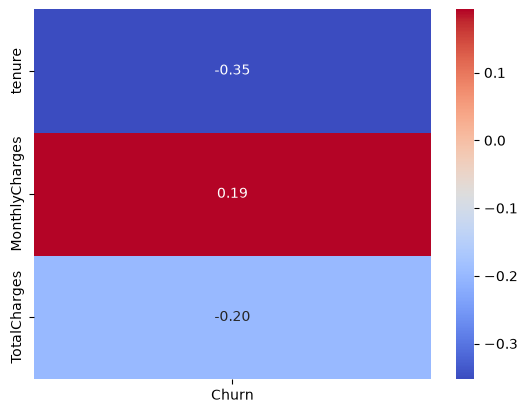

In [178]:
numerical_features_corr = df[numerical_features + ['Churn']].corr()[['Churn']].drop(index='Churn')
sns.heatmap(numerical_features_corr, cmap='coolwarm', annot=True, fmt='0.2f')
plt.show()

# Model Pipeline

In [179]:
X = df.drop(columns=['customerID', 'Churn'])
y = df['Churn']

In [181]:
X_train, X_test, y_train, y_test = train_test_split(X, y, stratify=y)

In [183]:
features_to_encode = categorical_features + [f for f in binary_features if f not in ['SeniorCitizen', 'Churn']]
preprocessor = ColumnTransformer(
    transformers=[
        ('num', MinMaxScaler(), numerical_features),
        ('cat', OneHotEncoder(handle_unknown='ignore'), features_to_encode)
    ],
    remainder='passthrough'
)

full_pipline =  Pipeline([
    ('preprocessing', preprocessor),
    ('model', 'passthrough')
])

In [184]:
df.head()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,0
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.50,0
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,1
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,0
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,1


In [185]:
param_grid = [{
        'model': [LogisticRegression()],
        'model__max_iter': [100, 250, 500, 1000],
        'model__class_weight': [None, 'balanced'],
        'model__C': [0.01, 0.1, 1, 10, 100]
    },
    {
        'model': [DecisionTreeClassifier()],
        'model__class_weight': [None, 'balanced'],
        'model__max_depth': [50, 100, 200, 300, 500]
    },
    {
        'model':[MultinomialNB()],
        'model__alpha':[0.01, 0.1, 1, 10, 100],
        'model__force_alpha': [True, False]
    },
    {
        'model':[GaussianNB()],
        'model__var_smoothing': [1e-9, 1e-8, 1e-7, 1e-6, 1e-5, 1e-4, 1e-3, 1e-2, 1e-1]
    }]
grid = GridSearchCV(full_pipline, param_grid, cv=5, scoring='f1_macro')

In [186]:
grid.fit(X_train, y_train)

,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",Pipeline(step...assthrough')])
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","[{'model': [LogisticRegression()], 'model__C': [0.01, 0.1, ...], 'model__class_weight': [None, 'balanced'], 'model__max_iter': [100, 250, ...]}, {'model': [DecisionTreeClassifier()], 'model__class_weight': [None, 'balanced'], 'model__max_depth': [50, 100, ...]}, ...]"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",'f1_macro'
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",5
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",None
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx_glr_auto_examples_model_selection_plot_grid_search_digits.py`to see how to design a custom selection strategy using a callablevia `refit`.See :ref:`this example<sphx_glr_auto_examples_model_selection_plot_grid_search_refit_callable.py>`for an example o

In [187]:
"""
GridSearchCV does two things:
- It performs cross-validation for all the parameter combinations.
- After finding the best parameters, it automatically fits the best model on the entire X_train, y_train.
"""

'\nGridSearchCV does two things:\n- It performs cross-validation for all the parameter combinations.\n- After finding the best parameters, it automatically fits the best model on the entire X_train, y_train.\n'

In [188]:
grid.best_params_

{'model': LogisticRegression(),
 'model__C': 100,
 'model__class_weight': None,
 'model__max_iter': 100}

In [189]:
grid.best_score_

np.float64(0.7367015081444308)

In [190]:
grid.best_estimator_

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessing', ...), ('model', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](19,)","['gender','SeniorCitizen','Partner',...,'PaymentMethod','MonthlyCharges', 'TotalCharges']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,19
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='p

In [191]:
# scores = cross_validate(grid, X_train, y_train, cv=5, scoring=['f1', 'precision', 'recall'])

# print('f1', scores['test_f1'].mean())
# print('precision', scores['test_precision'].mean())
# print('recall', scores['test_recall'].mean())

In [192]:
results = pd.DataFrame(grid.cv_results_)[['param_model', 'mean_test_score']]
results['param_model'] = results['param_model'].apply(lambda m: type(m).__name__)
results

,param_model,mean_test_score
0,LogisticRegression,0.708252
1,LogisticRegression,0.708252
2,LogisticRegression,0.708252
3,LogisticRegression,0.708252
4,LogisticRegression,0.708789
...,...,...
64,GaussianNB,0.672852
65,GaussianNB,0.672852
66,GaussianNB,0.673092
67,GaussianNB,0.672074


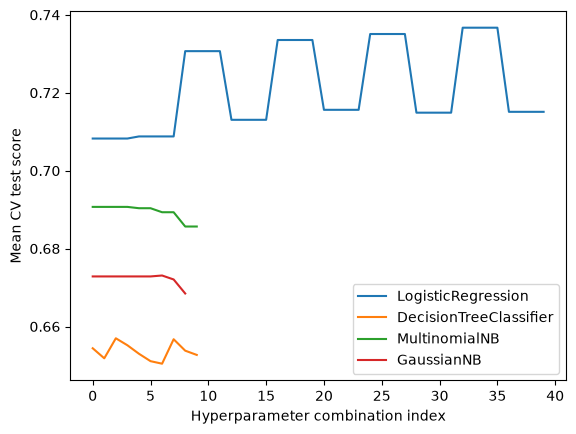

In [193]:
for model in ['LogisticRegression', 'DecisionTreeClassifier', 'MultinomialNB', 'GaussianNB']:
  plt.plot(results[results['param_model'] == model]['mean_test_score'].reset_index(drop=True), label = model)
plt.legend()
plt.xlabel('Hyperparameter combination index')
plt.ylabel('Mean CV test score')
plt.show()

In [195]:
y_pred = grid.predict(X_test)
print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

           0       0.85      0.88      0.86      1294
           1       0.63      0.57      0.60       467

    accuracy                           0.80      1761
   macro avg       0.74      0.73      0.73      1761
weighted avg       0.79      0.80      0.79      1761



0.847685248006778


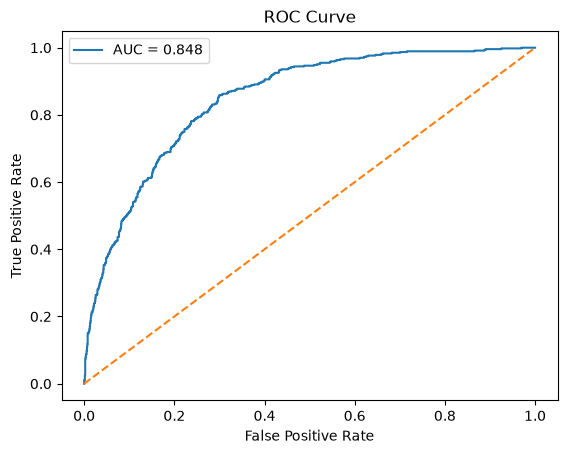

In [196]:
y_proba = grid.predict_proba(X_test)[:, 1]
roc_auc = roc_auc_score(y_test, y_proba)
print(roc_auc)

fpr, tpr, thresholds = roc_curve(y_test, y_proba)
plt.plot(fpr, tpr, label=f"AUC = {roc_auc:.3f}")
plt.plot([0, 1], [0, 1], linestyle="--")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve")
plt.legend()
plt.show()

In [197]:
print(grid.feature_names_in_)

['gender' 'SeniorCitizen' 'Partner' 'Dependents' 'tenure' 'PhoneService'
 'MultipleLines' 'InternetService' 'OnlineSecurity' 'OnlineBackup'
 'DeviceProtection' 'TechSupport' 'StreamingTV' 'StreamingMovies'
 'Contract' 'PaperlessBilling' 'PaymentMethod' 'MonthlyCharges'
 'TotalCharges']


# Save Model and Features (Data Types)

In [ ]:
best_model = grid.best_estimator_
joblib.dump(best_model, "best_model.joblib")

['best_model.joblib']

In [217]:
features_types = X.dtypes.astype(str).to_dict()
for feature, itstype in features_types.items():
    if itstype == 'str':
        features_types[feature] = X[feature].dropna().unique().tolist()
joblib.dump(features_types, "features_types.joblib")

['features_types.joblib']

# Test Model Pipline and Final Prediction

In [199]:
test_record = X_test.iloc[4, :]
test_record = test_record.to_frame().T
test_record

,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges
5442,Female,0,No,Yes,61,Yes,Yes,No,No internet service,No internet service,No internet service,No internet service,No internet service,No internet service,Two year,Yes,Credit card (automatic),25.0,1498.35


In [200]:
test_prediction = y_test.iloc[4]
test_prediction

np.int64(0)

In [201]:
load_best_model = joblib.load("./best_model.joblib")

In [202]:
prediction = load_best_model.predict(test_record)
prediction

array([0])

In [203]:
prediction[0]

np.int64(0)